# K-means：`import ... as ...` 與 `from ... import ...` 的寫法比較

本版本將前面的匯入敘述，在可以互換的情況下改寫，並同步修改後面的程式碼。

| 原寫法 | 修改後 | 說明 |
|---|---|---|
| `import pandas as pd` | `from pandas import read_excel, DataFrame` | 可以改，但後面的 `pd.read_excel()`、`pd.DataFrame()` 要同步修改。 |
| `from sklearn.preprocessing import StandardScaler` | `import sklearn.preprocessing as preprocessing` | 可以改，但後面要使用 `preprocessing.StandardScaler()`。 |
| `from sklearn.cluster import KMeans` | `import sklearn.cluster as cluster` | 可以改，但後面要使用 `cluster.KMeans()`。 |
| `import matplotlib.pyplot as plt` | `from matplotlib import pyplot as plt` | 可以互換，後面的 `plt` 不需修改。 |

## 注意

`StandardScaler` 與 `KMeans` 是 **class（類別）**，不是 module（模組），所以不能直接寫成：

```python
import sklearn.preprocessing.StandardScaler as StandardScaler
import sklearn.cluster.KMeans as KMeans
```

這種寫法會產生錯誤。因此使用「匯入模組，再透過模組名稱存取 class」的方式。


原始資料：
    Age  Income
0    40       5
1    44      14
2    71       2
3    46       6
4    63       3
5    49      11
6    22      13
7    59       0
8    38      10
9    46      10
10   55      18
11   43       8
12   43      11
13   57      14
14   49      17
15   35       8
16   44      10
17   28      10
18   41       8
19   45      10

=== 20筆資料的歸屬群組 ===
    Age  Income  Cluster
0    40       5        1
1    44      14        2
2    71       2        0
3    46       6        1
4    63       3        0
5    49      11        2
6    22      13        1
7    59       0        0
8    38      10        1
9    46      10        1
10   55      18        2
11   43       8        1
12   43      11        1
13   57      14        2
14   49      17        2
15   35       8        1
16   44      10        1
17   28      10        1
18   41       8        1
19   45      10        1

=== 三個群中心（標準化後） ===
          Age_std  Income_std
Group 0  1.656766   -1.698096
Group 1 -0.597694   -0.069534
Gr

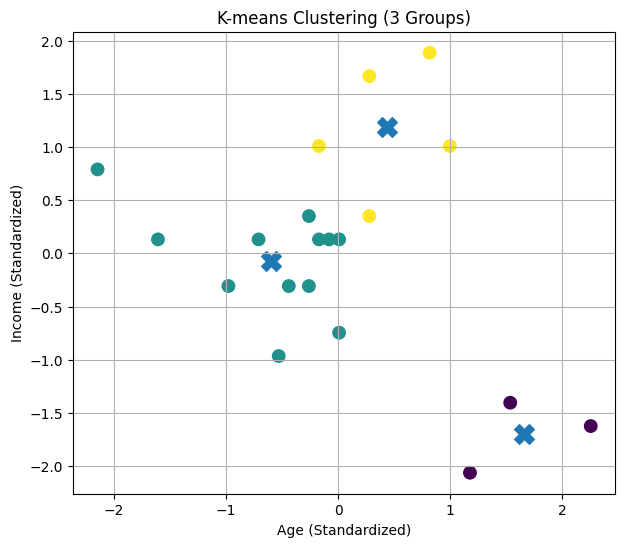

In [3]:
from pandas import read_excel, DataFrame
import sklearn.preprocessing as preprocessing
import sklearn.cluster as cluster
from matplotlib import pyplot as plt

# ======================================
# 1. 讀取 Excel （請修改你的檔案名稱）
# ======================================
#df = read_excel("1.K-means-上課範例3-題目.20筆.xlsx")   # <-- 你的 Excel 名稱
df = read_excel("/content/drive/MyDrive/資料探勘_程式資料夾/1.K-means-上課範例3-題目.20筆.xlsx")

df = df[['Age', 'Income']]        # 只取需要欄位

print("原始資料：")
print(df)

# ======================================
# 2. 標準化 Standardization
# ======================================
scaler = preprocessing.StandardScaler()
scaled_data = scaler.fit_transform(df)

scaled_df = DataFrame(scaled_data, columns=['Age_std', 'Income_std'])

# ======================================
# 3. K-means 分群（3 群）
# ======================================
kmeans = cluster.KMeans(n_clusters=3, random_state=42)
clusters = kmeans.fit_predict(scaled_df)

df['Cluster'] = clusters  # 將結果加入原資料

print("\n=== 20筆資料的歸屬群組 ===")
print(df)

# ======================================
# 4. 三個群中心（標準化後的 mean 座標）
# ======================================
centers = kmeans.cluster_centers_
centers_df = DataFrame(centers, columns=['Age_std', 'Income_std'])
centers_df.index = ['Group 0', 'Group 1', 'Group 2']

print("\n=== 三個群中心（標準化後） ===")
print(centers_df)

# ======================================
# 5. 描述三群資料特性（以平均值描述）
# ======================================
print("\n=== 三個群組的特性 ===")
for i in range(3):
    group_data = df[df['Cluster'] == i][['Age', 'Income']]
    print(f"\n群組 {i}:")
    print(group_data.describe())

# ======================================
# 6. 畫散佈圖（含群中心）
# ======================================
plt.figure(figsize=(7,6))
plt.scatter(scaled_df['Age_std'], scaled_df['Income_std'], c=clusters, s=80)

# 畫群中心
plt.scatter(centers[:,0], centers[:,1], marker='X', s=200)

plt.title("K-means Clustering (3 Groups)")
plt.xlabel("Age (Standardized)")
plt.ylabel("Income (Standardized)")
plt.grid(True)
plt.show()


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive
